自编码器学习的是：先把图像压缩成少量数字，再根据这些数字尽可能还原原图。

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

print("Single-thread configuration applied.")

Single-thread configuration applied.


In [2]:
#准备数据检查输入
import torch
from torch import nn
from torchvision import datasets, transforms

seed = 42
torch.manual_seed(seed)

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

train_dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

image, label = train_dataset[0]
inputs = image.reshape(1, -1)

print("Device:", device)
print("Training samples:", len(train_dataset))
print("Original image shape:", image.shape)
print("Model input shape:", inputs.shape)
print("Digit label:", label)

100%|██████████| 9.91M/9.91M [00:01<00:00, 7.59MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 199kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 1.90MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.71MB/s]

Device: mps
Training samples: 60000
Original image shape: torch.Size([1, 28, 28])
Model input shape: torch.Size([1, 784])
Digit label: 5


In [3]:
#搭建编码器
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 16)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        z = self.fc3(x)
        return z

torch.manual_seed(seed)
encoder = Encoder().to(device)

inputs = inputs.to(device)

encoder.eval()
with torch.no_grad():
    latent = encoder(inputs)

print("Input shape:", inputs.shape)
print("Latent shape:", latent.shape)
print("Latent representation:")
print(latent.cpu())

Input shape: torch.Size([1, 784])
Latent shape: torch.Size([1, 16])
Latent representation:
tensor([[ 0.0844, -0.0619,  0.0274, -0.0243, -0.0477, -0.1514, -0.1804,  0.0417,
         -0.0919,  0.0115,  0.0189,  0.0628,  0.0268, -0.0097, -0.0337, -0.0398]])


z = self.fc3(x) 中的 z 是什么？

在表示学习中，经常用：

- \(x\)：表示原始输入。
- \(z\)：表示经过编码后的潜在表示。
所以这里的计算关系可以写成：
$$
z = f_{\theta}(x)
$$
其中，f 就是编码器，$\theta$ 代表编码器中的全部权重和偏置。变量名 z 是一种常见约定。

In [4]:
#搭建解码器
class Decoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(16, 64)
        self.fc2 = nn.Linear(64, 256)
        self.fc3 = nn.Linear(256, 784)
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, z):
        x = self.relu(self.fc1(z))
        x = self.relu(self.fc2(x))
        reconstruction = self.sigmoid(self.fc3(x))
        return reconstruction

decoder = Decoder().to(device)

decoder.eval()
with torch.no_grad():
    reconstruction = decoder(latent)

print("Latent shape:", latent.shape)
print("Reconstruction shape:", reconstruction.shape)
print("Minimum pixel value:", reconstruction.min().item())
print("Maximum pixel value:", reconstruction.max().item())

Latent shape: torch.Size([1, 16])
Reconstruction shape: torch.Size([1, 784])
Minimum pixel value: 0.45717430114746094
Maximum pixel value: 0.5419727563858032


解码器的结构
| 层 | 输入特征数 | 输出特征数 |
|---|---:|---:|
| 第一个 Linear | 16 | 64 |
| 第二个 Linear | 64 | 256 |
| 第三个 Linear | 256 | 784 |

为什么最后要使用 Sigmoid？

我们的原图经过 ToTensor() 后，像素值范围是 0～1。因此，希望解码器生成的像素也处在相同范围。

为什么现在的像素值可能集中在 0.5 附近？

编码器和解码器都还没有训练。如果最后一个 Linear 层的输出大多接近 0，经过 Sigmoid 后就会接近：
$$
\sigma(0)=0.5
$$

In [5]:
#组合完整的 Autoencoder，计算重建损失（reconstruction loss）
class Autoencoder(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        x = x.reshape(x.shape[0], -1)
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction

autoencoder = Autoencoder(encoder, decoder).to(device)
loss_fn = nn.MSELoss()

autoencoder.eval()
with torch.no_grad():
    reconstruction = autoencoder(inputs)
    reconstruction_loss = loss_fn(reconstruction, inputs)

print("Input shape:", inputs.shape)
print("Reconstruction shape:", reconstruction.shape)
print(f"Reconstruction MSE: {reconstruction_loss.item():.6f}")

Input shape: torch.Size([1, 784])
Reconstruction shape: torch.Size([1, 784])
Reconstruction MSE: 0.228622


In [6]:
#训练自编码器
from torch.utils.data import DataLoader

batch_size = 64
learning_rate = 0.001

generator = torch.Generator().manual_seed(seed)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    generator=generator
)

optimizer = torch.optim.Adam(
    autoencoder.parameters(),
    lr=learning_rate
)

print("Training batches:", len(train_loader))

Training batches: 938


In [7]:
#定义训练函数
def train_autoencoder_one_epoch(model, data_loader, loss_fn, optimizer, device):
    model.train()

    total_loss = 0.0
    total_samples = 0

    for batch_index, (batch_images, _) in enumerate(data_loader, start=1):
        batch_inputs = batch_images.reshape(batch_images.shape[0], -1).to(device)

        optimizer.zero_grad(set_to_none=True)

        reconstruction = model(batch_inputs)
        loss = loss_fn(reconstruction, batch_inputs)

        loss.backward()
        optimizer.step()

        current_batch_size = batch_inputs.shape[0]
        total_loss += loss.item() * current_batch_size
        total_samples += current_batch_size

        if batch_index % 300 == 0 or batch_index == len(data_loader):
            print(f"Batch {batch_index}/{len(data_loader)} | MSE: {loss.item():.6f}")

    return total_loss / total_samples

train_mse_1 = train_autoencoder_one_epoch(
    autoencoder, train_loader, loss_fn, optimizer, device
)

ae_history = [{"epoch": 1, "train_mse": train_mse_1}]

print(f"Epoch 1 training MSE: {train_mse_1:.6f}")

Batch 300/938 | MSE: 0.042120
Batch 600/938 | MSE: 0.031492
Batch 900/938 | MSE: 0.025930
Batch 938/938 | MSE: 0.025077
Epoch 1 training MSE: 0.041987


In [8]:
#准备测试数据：固定取测试集前8张图片进行重建
import matplotlib.pyplot as plt

test_dataset = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

sample_images, sample_labels = next(iter(test_loader))

num_images = 8
sample_inputs = sample_images[:num_images].reshape(num_images, -1).to(device)

autoencoder.eval()
with torch.no_grad():
    sample_reconstructions = autoencoder(sample_inputs)

reconstructed_images = sample_reconstructions.cpu().reshape(num_images, 28, 28)

print("Original batch shape:", sample_images[:num_images].shape)
print("Reconstructed image shape:", reconstructed_images.shape)

Original batch shape: torch.Size([8, 1, 28, 28])
Reconstructed image shape: torch.Size([8, 28, 28])


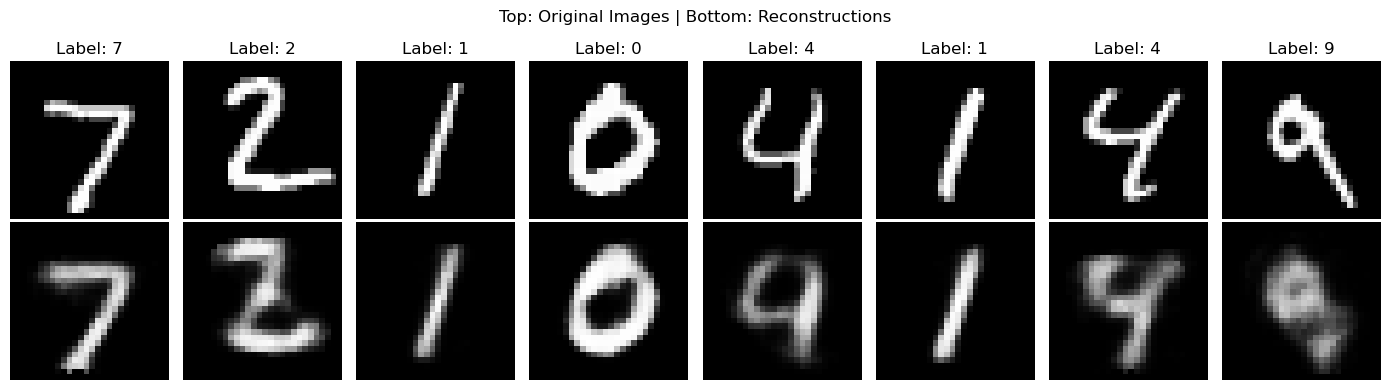

In [9]:
#显示原图与重建图
fig, axes = plt.subplots(2, num_images, figsize=(14, 4))

for i in range(num_images):
    axes[0, i].imshow(
        sample_images[i, 0].numpy(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[0, i].set_title(f"Label: {sample_labels[i].item()}")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed_images[i].numpy(),
        cmap="gray", vmin=0, vmax=1
    )
    axes[1, i].axis("off")

fig.suptitle("Top: Original Images | Bottom: Reconstructions")
plt.tight_layout()
plt.show()

In [10]:
#保存第一轮的对比图和模型
from pathlib import Path

ae_output_dir = Path("week3_ae_results")
ae_output_dir.mkdir(parents=True, exist_ok=True)

epoch1_reconstructed_images = reconstructed_images.clone()

fig.savefig(
    ae_output_dir / "reconstruction_epoch1.png",
    dpi=300,
    bbox_inches="tight"
)

torch.save(
    autoencoder.state_dict(),
    ae_output_dir / "autoencoder_epoch1.pth"
)

print("Epoch 1 results saved to:", ae_output_dir.resolve())

Epoch 1 results saved to: /Users/cheeseowl/Desktop/科研/week3_ae_results


In [11]:
#继续训练剩下9轮
total_epochs = 10
start_epoch = ae_history[-1]["epoch"] + 1

for epoch in range(start_epoch, total_epochs + 1):
    train_mse = train_autoencoder_one_epoch(
        autoencoder, train_loader, loss_fn, optimizer, device
    )

    ae_history.append({
        "epoch": epoch,
        "train_mse": train_mse
    })

    print(f"Epoch {epoch}/{total_epochs} | Training MSE: {train_mse:.6f}")

Batch 300/938 | MSE: 0.023898
Batch 600/938 | MSE: 0.022377
Batch 900/938 | MSE: 0.020017
Batch 938/938 | MSE: 0.019703
Epoch 2/10 | Training MSE: 0.022368
Batch 300/938 | MSE: 0.020323
Batch 600/938 | MSE: 0.017407
Batch 900/938 | MSE: 0.017433
Batch 938/938 | MSE: 0.018053
Epoch 3/10 | Training MSE: 0.018001
Batch 300/938 | MSE: 0.015951
Batch 600/938 | MSE: 0.015059
Batch 900/938 | MSE: 0.016111
Batch 938/938 | MSE: 0.015836
Epoch 4/10 | Training MSE: 0.015961
Batch 300/938 | MSE: 0.014949
Batch 600/938 | MSE: 0.014265
Batch 900/938 | MSE: 0.013817
Batch 938/938 | MSE: 0.013295
Epoch 5/10 | Training MSE: 0.014495
Batch 300/938 | MSE: 0.014412
Batch 600/938 | MSE: 0.012598
Batch 900/938 | MSE: 0.013637
Batch 938/938 | MSE: 0.012936
Epoch 6/10 | Training MSE: 0.013389
Batch 300/938 | MSE: 0.015360
Batch 600/938 | MSE: 0.013549
Batch 900/938 | MSE: 0.012263
Batch 938/938 | MSE: 0.011900
Epoch 7/10 | Training MSE: 0.012545
Batch 300/938 | MSE: 0.011139
Batch 600/938 | MSE: 0.011047
Batc

 epoch  train_mse
     1   0.041987
     2   0.022368
     3   0.018001
     4   0.015961
     5   0.014495
     6   0.013389
     7   0.012545
     8   0.011986
     9   0.011549
    10   0.011212


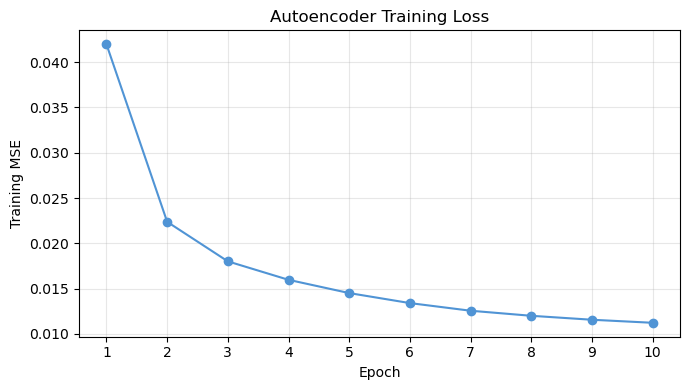

In [12]:
#绘制训练损失曲线
import pandas as pd

ae_history_df = pd.DataFrame(ae_history)
print(ae_history_df.to_string(index=False))

loss_fig, loss_ax = plt.subplots(figsize=(7, 4))

loss_ax.plot(
    ae_history_df["epoch"],
    ae_history_df["train_mse"],
    marker="o",
    color="#5094D5"
)

loss_ax.set_xlabel("Epoch")
loss_ax.set_ylabel("Training MSE")
loss_ax.set_title("Autoencoder Training Loss")
loss_ax.set_xticks(ae_history_df["epoch"])
loss_ax.grid(True, alpha=0.3)

loss_fig.tight_layout()
loss_fig.savefig(
    ae_output_dir / "autoencoder_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

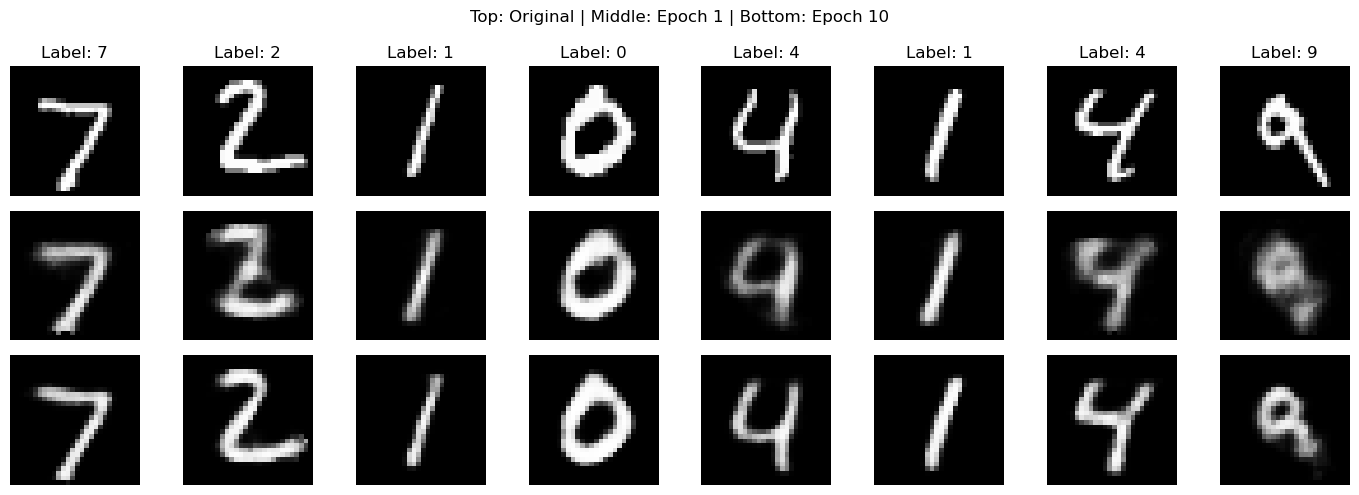

In [13]:
#用第十轮模型重新生成重建图像
autoencoder.eval()

with torch.no_grad():
    epoch10_reconstructed_images = autoencoder(sample_inputs).cpu().reshape(
        num_images, 28, 28
    )

image_rows = [
    sample_images[:num_images, 0],
    epoch1_reconstructed_images,
    epoch10_reconstructed_images
]

comparison_fig, axes = plt.subplots(
    3, num_images, figsize=(14, 5)
)

for row_index, row_images in enumerate(image_rows):
    for image_index in range(num_images):
        axes[row_index, image_index].imshow(
            row_images[image_index].numpy(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row_index, image_index].axis("off")

        if row_index == 0:
            axes[row_index, image_index].set_title(
                f"Label: {sample_labels[image_index].item()}"
            )

comparison_fig.suptitle(
    "Top: Original | Middle: Epoch 1 | Bottom: Epoch 10"
)
comparison_fig.tight_layout()
comparison_fig.savefig(
    ae_output_dir / "reconstruction_epoch1_vs_epoch10.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [14]:
#保存第十轮模型并提取训练后的 16 维潜在表示，为 K-means 聚类做准备
import numpy as np

torch.save(
    autoencoder.state_dict(),
    ae_output_dir / "autoencoder_epoch10.pth"
)

def extract_representations(model, data_loader, device):
    model.eval()

    raw_batches = []
    latent_batches = []
    label_batches = []

    with torch.no_grad():
        for batch_images, batch_labels in data_loader:
            batch_inputs = batch_images.reshape(
                batch_images.shape[0], -1
            ).to(device)

            batch_latent = model.encoder(batch_inputs)

            raw_batches.append(batch_inputs.cpu().numpy())
            latent_batches.append(batch_latent.cpu().numpy())
            label_batches.append(batch_labels.numpy())

    raw_pixels = np.concatenate(raw_batches, axis=0)
    latent_features = np.concatenate(latent_batches, axis=0)
    labels = np.concatenate(label_batches, axis=0)

    return raw_pixels, latent_features, labels

raw_pixels, latent_features, true_labels = extract_representations(
    autoencoder, test_loader, device
)

print("Raw pixel shape:", raw_pixels.shape)
print("Latent feature shape:", latent_features.shape)
print("Label shape:", true_labels.shape)

Raw pixel shape: (10000, 784)
Latent feature shape: (10000, 16)
Label shape: (10000,)


In [15]:
np.savez_compressed(
    ae_output_dir / "clustering_features.npz",
    raw_pixels=raw_pixels,
    latent_features=latent_features,
    true_labels=true_labels
)
print("Clustering features saved.")

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from threadpoolctl import threadpool_limits

raw_kmeans = KMeans(
    n_clusters=10,
    init="k-means++",
    n_init=10,
    random_state=42
)

with threadpool_limits(limits=1):
    raw_clusters = raw_kmeans.fit_predict(raw_pixels)

raw_ari = adjusted_rand_score(true_labels, raw_clusters)
raw_nmi = normalized_mutual_info_score(true_labels, raw_clusters)

print(f"Raw pixel ARI: {raw_ari:.4f}")
print(f"Raw pixel NMI: {raw_nmi:.4f}")

Clustering features saved.
Raw pixel ARI: 0.3791
Raw pixel NMI: 0.5017


In [16]:
latent_kmeans = KMeans(
    n_clusters=10,
    init="k-means++",
    n_init=10,
    random_state=42
)

with threadpool_limits(limits=1):
    latent_clusters = latent_kmeans.fit_predict(latent_features)

latent_ari = adjusted_rand_score(true_labels, latent_clusters)
latent_nmi = normalized_mutual_info_score(true_labels, latent_clusters)

print("Latent cluster shape:", latent_clusters.shape)
print(f"AE latent ARI: {latent_ari:.4f}")
print(f"AE latent NMI: {latent_nmi:.4f}")

Latent cluster shape: (10000,)
AE latent ARI: 0.3509
AE latent NMI: 0.4936


为什么图像重建更清楚，聚类却没有提高？

模型优化的是重建像素与原始像素之间的误差。

这个目标会推动模型保留有助于重建的信息，但没有直接要求：
- 同一个数字的不同写法，在潜在空间里靠近。
- 不同数字的表示，在潜在空间里分开。
因此，重建误差较小，并不能保证潜在空间适合按数字类别聚类。

当前结果有哪些可能的解释？

以下是合理假设，还不能当作已经验证的原因：
| 可能的解释 | 含义 |
|---|---|
| 重建目标与类别分组目标不同 | 有助于还原像素的特征，不一定最适合区分数字类别 |
| 压缩过程丢失了部分信息 | 16 维表示可能没有充分保留某些区分类别的细节 |
| 潜在空间的距离关系不够合适 | 当前直接对编码器输出使用欧式距离，距离较近未必代表属于同一数字 |

In [17]:
#保存对比结果
import pandas as pd

clustering_results = pd.DataFrame([
    {
        "representation": "Raw pixels",
        "dimension": raw_pixels.shape[1],
        "n_samples": len(true_labels),
        "k": 10,
        "ARI": raw_ari,
        "NMI": raw_nmi
    },
    {
        "representation": "AE latent",
        "dimension": latent_features.shape[1],
        "n_samples": len(true_labels),
        "k": 10,
        "ARI": latent_ari,
        "NMI": latent_nmi
    }
])

clustering_results.to_csv(
    ae_output_dir / "clustering_comparison.csv",
    index=False
)

cluster_assignments = pd.DataFrame({
    "true_label": true_labels,
    "raw_pixel_cluster": raw_clusters,
    "ae_latent_cluster": latent_clusters
})

cluster_assignments.to_csv(
    ae_output_dir / "cluster_assignments.csv",
    index=False
)

print("Clustering comparison and assignments saved.")
clustering_results.round(4)

Clustering comparison and assignments saved.


,representation,dimension,n_samples,k,ARI,NMI
0,Raw pixels,784,10000,10,0.3791,0.5017
1,AE latent,16,10000,10,0.3509,0.4936


## 实验总结：自编码器重建与潜在表示聚类

### 一、实验目的

使用 PyTorch 搭建自编码器（Autoencoder，AE），将 MNIST 图像从 784 维像素表示压缩为 16 维潜在表示，再通过解码器重建图像。

随后，对同一批图像分别使用原始像素和 AE 潜在表示进行 K-means 聚类，比较两种表示与真实数字类别的一致性。

### 二、实验设置

| 项目 | 设置 |
|---|---|
| 数据集 | MNIST |
| AE 训练集 | 官方训练集，60,000 张图像 |
| 重建展示与聚类数据 | 官方测试集，10,000 张图像 |
| 图像大小 | 单通道，28 × 28 |
| 输入预处理 | 使用 ToTensor，将像素值缩放到 0～1 |
| 输入维度 | 展平后的 784 个像素特征 |
| 编码器 | 784 → 256 → 64 → 16 |
| 潜在表示维度 | 16 |
| 解码器 | 16 → 64 → 256 → 784 |
| 隐藏层激活函数 | ReLU |
| 解码器输出激活函数 | Sigmoid |
| 重建损失 | 均方误差（MSE） |
| 优化器 | Adam，使用默认 betas，不使用权重衰减 |
| 学习率 | 0.001 |
| 批次大小 | 64 |
| 训练轮数 | 10 |
| 随机种子 | 42 |

AE 训练时不使用数字标签，而是将输入图像本身作为重建目标。标签仅用于展示图像类别和聚类完成后的评价。

### 三、模型原理与训练过程

编码器将图像像素转换成潜在表示：

$$
z = f_{\theta}(x)
$$

解码器根据潜在表示生成重建图像：

$$
\hat{x} = g_{\phi}(z)
$$

其中，$x$ 是原始图像的像素向量，$z$ 是 16 维潜在表示，$\hat{x}$ 是重建像素，$\theta$ 和 $\phi$ 分别表示编码器与解码器的参数。

编码器最后一层直接输出连续数值，因此潜在表示可以包含正数和负数。解码器最后使用 Sigmoid，将输出限制在 0～1 的范围，与原始像素范围一致。

对于包含 $B$ 张图像的批次，重建损失为：

$$
L_{\mathrm{MSE}}
=
\frac{1}{B \times 784}
\sum_{i=1}^{B}
\sum_{j=1}^{784}
(\hat{x}_{ij}-x_{ij})^2
$$

每个批次依次完成清除梯度、前向传播、计算重建损失、反向传播和参数更新。编码器与解码器通过同一个重建目标共同训练。

### 四、训练损失结果

| Epoch | 训练过程平均 MSE |
|---:|---:|
| 1 | 0.041987 |
| 2 | 0.022368 |
| 3 | 0.018001 |
| 4 | 0.015961 |
| 5 | 0.014495 |
| 6 | 0.013389 |
| 7 | 0.012545 |
| 8 | 0.011986 |
| 9 | 0.011549 |
| 10 | 0.011212 |

训练 MSE 从第一轮的 0.041987 降至第十轮的 0.011212，十轮之间持续下降。

早期损失下降较快，后期仍在改善，但每轮的下降幅度逐渐减小。这说明模型逐步学会利用 16 维表示重建输入图像。

上述指标是在训练过程中，按样本数量加权汇总各批次损失得到的平均值。由于模型参数在每轮内持续更新，它不是训练结束后固定模型重新计算的损失，也不是测试集重建 MSE。

### 五、重建效果观察

固定选择测试集前 8 张图像，展示原图、第一轮重建图和第十轮重建图。

第一轮结束后，模型已经能够重建多数数字的大致轮廓，但图像边缘较模糊，部分笔画出现粘连或变形。

第十轮结束后，数字轮廓和部分笔画细节更加清楚，重建结果整体更接近原图，但仍然存在模糊、笔画粗细变化和局部结构差异。

重建图像用于检查模型保留了哪些视觉信息。少量样本的视觉改善不能直接证明潜在表示更适合聚类，因此还需要进行定量比较。

### 六、聚类实验方法

使用训练十轮后的编码器，为全部 10,000 张测试图像提取 16 维潜在表示。

| 数据 | 形状 |
|---|---|
| 原始像素 | 10000 × 784 |
| AE 潜在表示 | 10000 × 16 |
| 真实数字标签 | 10000 |

提取过程中，同一张图像的原始像素、潜在表示和标签保持一一对应，样本顺序一致。

分别对两种表示使用相同的 K-means 设置：

- 簇数量：K = 10。
- 初始化方式：k-means++。
- 初始化次数：n_init = 10。
- 随机种子：random_state = 42。
- 线程限制：1。
- 直接使用各自的特征，不增加额外标准化。

K-means 拟合时只使用特征。真实标签不参与聚类训练，仅在分组完成后用于计算 ARI 和 NMI。

两种 K-means 都在这同一批 10,000 个样本上拟合并分组。因此，结果评价的是这些样本自身的聚类一致性，不是对另一批独立留出样本的预测表现。

### 七、聚类结果与比较

| 表示 | 维度 | ARI | NMI |
|---|---:|---:|---:|
| 原始像素 | 784 | 0.3791 | 0.5017 |
| AE 潜在表示 | 16 | 0.3509 | 0.4936 |

以“AE 潜在表示减去原始像素”计算：

- ARI 差值为 −0.0282。
- NMI 差值为 −0.0081。

两项指标均下降。因此，在本次网络结构、训练配置和 K-means 设置下，AE 潜在表示没有改善按照数字类别进行聚类的表现。

ARI 和 NMI 衡量聚类分组与真实类别的一致性，不应解释为分类准确率。

### 八、问题讨论

#### 1. 表示学习是否改善了本次聚类？

没有。

虽然 AE 将每张图像的表示从 784 维减少到 16 维，并能够重建数字图像，但潜在表示的 ARI 和 NMI 均低于原始像素。

因此，本次实验实现了表示压缩和图像重建，但没有获得更符合真实数字类别的 K-means 分组。

#### 2. 为什么压缩表示可能使聚类更容易？

如果编码器能够减少冗余信息和无关变化，同时保留区分类别的重要结构，那么同类样本可能在潜在空间中更加接近，从而帮助聚类。

例如，学到的表示可能减少位置、粗细或倾斜变化的影响，同时保留数字的主要结构。

但是，这取决于实际学到的特征。维度降低本身不能保证聚类效果提高。

#### 3. 为什么重建改善没有带来聚类改善？

AE 优化的是像素重建误差，没有直接要求同一类别的样本靠近，也没有直接要求不同类别的样本分开。

可能的解释包括：

- 有利于重建像素的信息，不一定最适合区分数字类别。
- 压缩过程可能丢失部分区分类别的细节。
- 当前潜在空间中的欧式距离，可能没有充分反映类别相似性。

这些解释属于待验证的假设，不能仅凭本次结果确定具体原因。

#### 4. 后续可以怎样研究？

可以一次改变一个因素，例如潜在维度、训练轮数或潜在特征的尺度处理，再比较聚类结果。

也可以使用多个随机种子重复实验，检查当前差异是否稳定。

本次结果只能说明当前配置没有改善聚类，不能推广为所有自编码器都不适合聚类。

### 九、运行配置与结果保存

实验过程中，K-means 曾触发底层段错误，并报告 OpenMP 线程锁初始化失败。限制线程数量后，小规模测试和正式聚类均成功完成。

Notebook 顶部设置 OMP_NUM_THREADS、OPENBLAS_NUM_THREADS 和 MKL_NUM_THREADS 为 1，并在正式聚类时使用 threadpool_limits(limits=1)。

正式流程从初始化模型开始训练。加载已有权重的恢复代码与从头训练流程分开，避免将额外训练误记为第一至第十轮。

保存内容包括：

- 第一轮和第十轮模型参数。
- 原图与重建图，以及不同训练阶段的重建对比图。
- 十轮训练损失曲线。
- clustering_features.npz：原始像素、潜在表示和真实标签。
- clustering_comparison.csv：两种表示的聚类评价结果。
- cluster_assignments.csv：每个样本的真实标签和簇编号。

### 十、实验结论

1. 自编码器能够通过无标签的图像重建任务学习 16 维表示，训练 MSE 从 0.041987 降至 0.011212。

2. 重建能力改善与类别聚类能力改善是两个不同问题，需要分别评估。

3. 本次 AE 潜在表示的 ARI 和 NMI 均低于原始像素，说明当前压缩表示没有改善 K-means 的数字类别聚类表现。